# Barlow Twins

Can two views of a digit agree without all feature coordinates learning the same thing? Barlow Twins sets a separate target for the diagonal and off-diagonal entries of a cross-correlation matrix.

The encoder and projection head share weights across the two views. The loss drives diagonal correlations towards one and the other correlations towards zero. Digit labels enter only after the encoder has been frozen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)


import copy
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import balanced_accuracy_score, f1_score


def digit_data():
    digits = load_digits()
    train, test = train_test_split(
        np.arange(len(digits.target)), test_size=0.25, stratify=digits.target, random_state=17
    )
    x = torch.tensor(digits.images[:, None], dtype=torch.float32) / 16
    return x[train], x[test], digits.target[train], digits.target[test]


def view(x):
    n = len(x)
    padded = F.pad(x, (1, 1, 1, 1))
    offset = torch.randint(3, (n, 2))
    row = offset[:, 0, None, None] + torch.arange(8)[None, :, None]
    col = offset[:, 1, None, None] + torch.arange(8)[None, None, :]
    moved = padded[torch.arange(n)[:, None, None], 0, row, col][:, None]
    return (moved + 0.06 * torch.randn_like(moved)).clamp(0, 1)


@torch.no_grad()
def embed(model, x):
    model.eval()
    return torch.cat([model(batch) for batch in x.split(96)]).flatten(1).numpy()


def compare(initial, trained, x, t, y, yt):
    systems = [
        ("Raw pixels", x.flatten(1).numpy(), t.flatten(1).numpy()),
        ("Random encoder", embed(initial, x), embed(initial, t)),
        ("Trained encoder", embed(trained, x), embed(trained, t)),
    ]
    rows = []
    for name, a, b in systems:
        probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1200, C=1))
        probe.fit(a, y)
        guess = probe.predict(b)
        power = np.linalg.svd(b - b.mean(0), compute_uv=False) ** 2
        p = power[power > 0] / max(power.sum(), 1e-30)
        rank = float(np.exp(-(p * np.log(p)).sum())) if len(p) else 0.0
        rows.append(
            (
                name,
                float((guess == yt).mean()),
                balanced_accuracy_score(yt, guess),
                f1_score(yt, guess, average="macro"),
                rank,
            )
        )
    report(["Features", "Test accuracy", "Balanced accuracy", "Macro F1", "Effective rank"], rows)


def conv_encoder():
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1),
        nn.GELU(),
        nn.AvgPool2d(2),
        nn.Conv2d(16, 24, 3, padding=1),
        nn.GELU(),
        nn.Flatten(),
        nn.Linear(24 * 4 * 4, 32),
    )


def correlation(z1, z2):
    def standard(z):
        return (z - z.mean(0)) / z.std(0, unbiased=False).clamp_min(1e-5)

    return standard(z1).T @ standard(z2) / len(z1)

## Optimise cross-view agreement

Translations of at most one pixel and independent additive noise generate the two views. Small final batches are skipped to keep the correlation estimate usable.

In [2]:
seed()
x, t, y, yt = digit_data()
net = conv_encoder()
initial = copy.deepcopy(net)
head = nn.Sequential(nn.Linear(32, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Linear(64, 24))
opt = torch.optim.AdamW([*net.parameters(), *head.parameters()], lr=0.002)
curve = []
off = ~torch.eye(24, dtype=torch.bool)
for epoch in range(18):
    terms = []
    for ids in torch.randperm(len(x)).split(96):
        if len(ids) < 32:
            continue
        corr = correlation(head(net(view(x[ids]))), head(net(view(x[ids]))))
        inv = (corr.diag() - 1).square().sum()
        redundancy = corr[off].square().sum()
        loss = inv + 0.02 * redundancy
        opt.zero_grad()
        loss.backward()
        opt.step()
        terms.append([inv.item(), 0.02 * redundancy.item()])
    curve.append(np.mean(terms, axis=0))

## Probe and inspect the cross-correlation

Fit a logistic probe on training features only. A separate pair of test views supplies the correlation heat map.

,Features,Test accuracy,Balanced accuracy,Macro F1,Effective rank
0,Raw pixels,0.97111,0.97084,0.97099,20.17443
1,Random encoder,0.96667,0.96650,0.96657,10.29035
2,Trained encoder,0.95556,0.95477,0.95476,4.83248


,Test views,Mean diagonal,Off-diagonal RMS
0,450,0.88828,0.26146


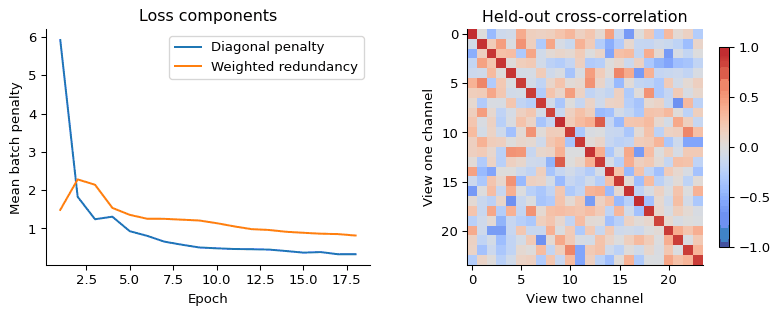

In [3]:
compare(initial, net, x, t, y, yt)
head.eval()
torch.manual_seed(89)
with torch.no_grad():
    corr = correlation(head(net(view(t))), head(net(view(t)))).numpy()
report(
    ["Test views", "Mean diagonal", "Off-diagonal RMS"],
    [(len(t), np.diag(corr).mean(), np.sqrt((corr[off.numpy()] ** 2).mean()))],
)
fig, axes = plt.subplots(1, 2, figsize=(8.1, 3.2), layout="constrained")
axes[0].plot(np.arange(1, len(curve) + 1), curve)
axes[0].legend(["Diagonal penalty", "Weighted redundancy"])
axes[0].set(xlabel="Epoch", ylabel="Mean batch penalty", title="Loss components")
im = axes[1].imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
axes[1].set(
    xlabel="View two channel", ylabel="View one channel", title="Held-out cross-correlation"
)
fig.colorbar(im, ax=axes[1], shrink=0.85)
plt.show()

## Interpreting the result

The test cross-correlation had a mean diagonal of 0.888 and an off-diagonal RMS of 0.261. The trained-feature probe classified 95.6% of test digits correctly, compared with 96.7% for the frozen random encoder.

The probe uses the 32 encoder features and the correlation plot uses the 24 projection features. They answer different questions about the same training run.

## Exercise

Increase the coefficient on off-diagonal terms and compare the probe result with the new cross-correlation matrix.

## References

[Zbontar et al. (2021), Barlow Twins](https://arxiv.org/abs/2103.03230)

[Alpaydin and Kaynak (1998), Optical Recognition of Handwritten Digits, UCI, CC BY 4.0](https://doi.org/10.24432/C50P49)